<>:50: SyntaxWarning: invalid escape sequence '\o'
<>:50: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_3479/2495442185.py:50: SyntaxWarning: invalid escape sequence '\o'
  ax2.set_ylabel('$|F(j\omega)|$')


=== Амплітудний спектр ===
k=0 (Частота 0.0 Гц): |F(jw)| = 1.29
k=1 (Частота 1.0 Гц): |F(jw)| = 2.16
k=2 (Частота 2.0 Гц): |F(jw)| = 1.92
k=3 (Частота 3.0 Гц): |F(jw)| = 0.61
k=4 (Частота 4.0 Гц): |F(jw)| = 0.61
k=5 (Частота -5.0 Гц): |F(jw)| = 0.79
k=6 (Частота -4.0 Гц): |F(jw)| = 0.61
k=7 (Частота -3.0 Гц): |F(jw)| = 0.61
k=8 (Частота -2.0 Гц): |F(jw)| = 1.92
k=9 (Частота -1.0 Гц): |F(jw)| = 2.16


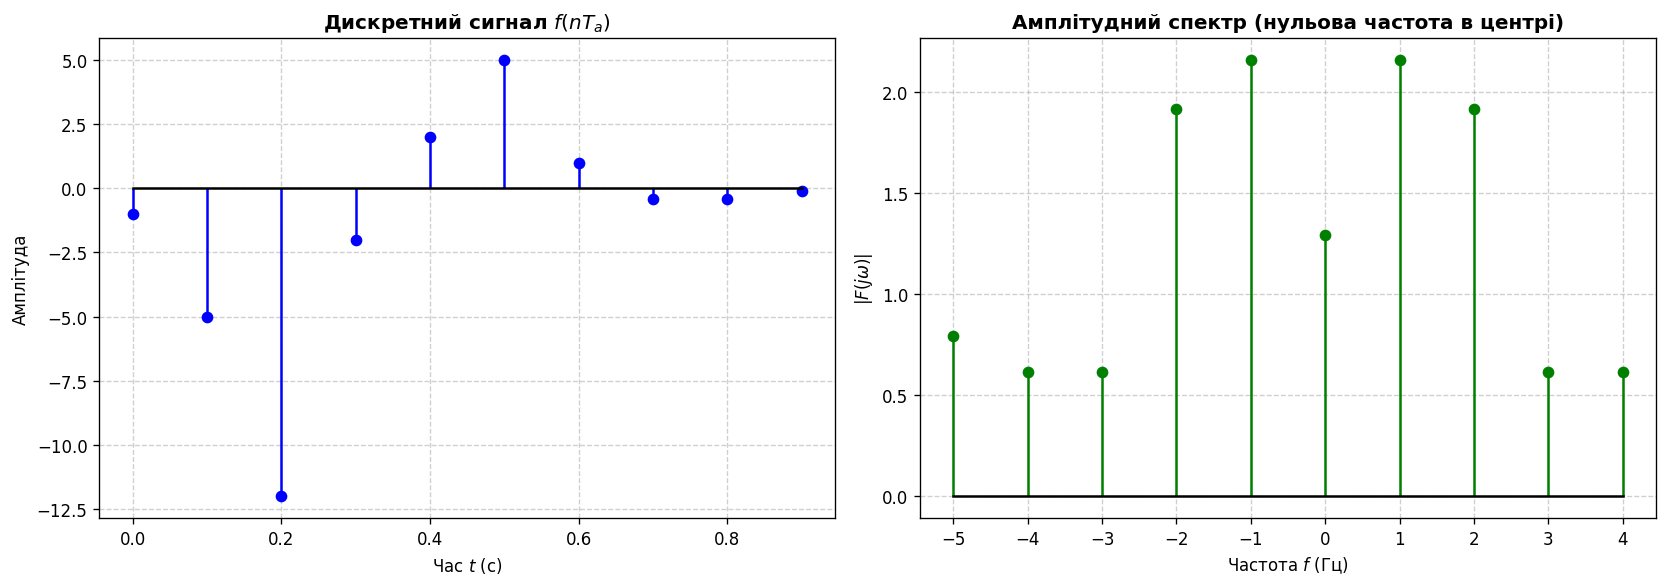

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. ВХІДНІ ДАНІ (Варіант 5)
N = 10
Ta = 0.1
fa = 1.0 / Ta

n = np.arange(N)
t = n * Ta
f_t = np.array([-1.0, -5.0, -12.0, -2.0, 2.0, 5.0, 1.0, -0.4, -0.4, -0.1])

# 2. ОБЧИСЛЕННЯ ДПФ (Аналог функцій Matlab: fft, abs)
F_d = np.fft.fft(f_t)

F_jw = Ta * F_d


amplitude_spectrum = np.abs(F_jw)

# 3. ЗСУВ СПЕКТРУ В ЦЕНТР (Аналог функції Matlab: fftshift)

freqs = np.fft.fftfreq(N, d=Ta)

freqs_shifted = np.fft.fftshift(freqs)
amplitude_spectrum_shifted = np.fft.fftshift(amplitude_spectrum)

print("=== Амплітудний спектр ===")
for k in range(N):
    print(f"k={k} (Частота {freqs[k]:.1f} Гц): |F(jw)| = {amplitude_spectrum[k]:.2f}")

# 4. ВІЗУАЛІЗАЦІЯ
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# Графік 1: Вихідний дискретний сигнал
ax1.stem(t, f_t, linefmt='b-', markerfmt='bo', basefmt='k-')
ax1.set_title('Дискретний сигнал $f(nT_a)$', fontweight='bold')
ax1.set_xlabel('Час $t$ (с)')
ax1.set_ylabel('Амплітуда')
ax1.grid(True, linestyle='--', alpha=0.6)

# Графік 2: Амплітудний спектр із нульовою частотою в центрі
ax2.stem(freqs_shifted, amplitude_spectrum_shifted, linefmt='g-', markerfmt='go', basefmt='k-')
ax2.set_title('Амплітудний спектр (нульова частота в центрі)', fontweight='bold')
ax2.set_xlabel('Частота $f$ (Гц)')
ax2.set_ylabel('$|F(j\omega)|$')
ax2.set_xticks(freqs_shifted)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('lab3_dft_spectrum.png', dpi=300)
plt.show()